In [1]:
import numpy as np
from matplotlib import pyplot as plt
import torch
from torch import nn
from torch import optim

In [2]:
# Parameters
# degree day melt factor
alpha = 0.05 # day-1 
# temperature lapse rate
gamma = -6.0/1e3 # deg.m-1
# Precipitation lapse rate defined following MicroMet
# maximum elevation difference for precipitation correction factor (beta)
dm = 1800. # m
# reference precipitation correction factor
beta_ref = 0.2/1e3 # m-1
# elevation range for the model
zmin = 2000
zmax = 3500
# AWS station elevation
z0 = zmin
# vertical grid (elevation bands)
zi_array = np.linspace(zmin,zmax)
# time vector
t = np.arange(0,365) # day of water year

In [3]:
def massbal(previous_swe_array,T0,P0,beta):
    """
    numpy implementation to calculate the new SWE array based on the previous SWE array, 
    temperature, and precipitation.
    """
    dz_array = zi_array - z0
    T_array = T0 + gamma * dz_array
    d_array = np.maximum(dz_array, dm)
    P_array = P0 * (1 + beta * d_array) / (1 - beta * d_array)
    Acc_array = P_array * (0.5 + 0.5 * np.tanh(-10 * T_array))
    Abl_array = np.minimum(previous_swe_array, alpha * T_array * np.heaviside(T_array,0))
    swe_array = previous_swe_array + Acc_array - Abl_array
    return swe_array

In [4]:
# generate synthetic P and T input data at z = z0
T0_series = 10 + 10 * np.cos(2*np.pi*t/365)
P0_series = 0.01 + 0.01 * np.cos(2*np.pi*t/365 + np.pi)
rng = np.random.default_rng(42)
ix = rng.choice(len(P0_series),int(np.round(0.8*len(t))),replace=False)
P0_series[ix] = 0

In [5]:
# run the mass balance model over a year with an explicit time stepping scheme
swe_array_previous = np.zeros_like(zi_array)
swe_array_series = np.zeros((*zi_array.shape,len(t)))
for it in range(len(t)) :
    it = t[it]
    T0 = T0_series[it]
    P0 = P0_series[it]
    swe_array_current = massbal(swe_array_previous,T0,P0,beta_ref)
    swe_array_series[:,it] = swe_array_current
    swe_array_previous = swe_array_current
mean_swe_series_target = swe_array_series.mean(axis=0)

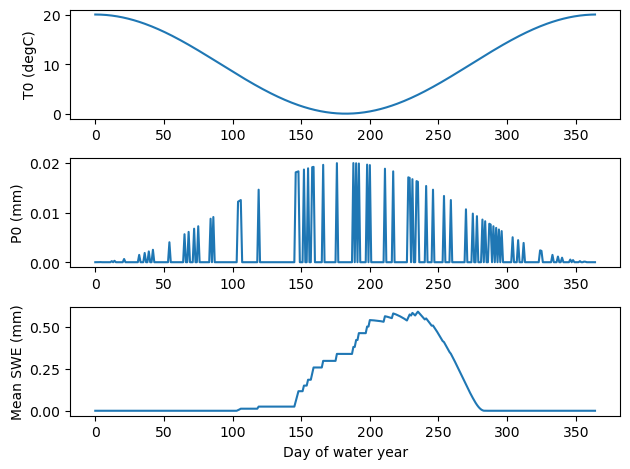

In [6]:
# plot the input and output time series
fig, axs = plt.subplots(3,1)
axs[0].plot(t, T0_series)
axs[0].set_ylabel('T0 (degC)')
axs[1].plot(t, P0_series)
axs[1].set_ylabel('P0 (mm)')
axs[2].plot(t, mean_swe_series_target)
axs[2].set_ylabel('Mean SWE (mm)')
axs[2].set_xlabel('Day of water year')
plt.tight_layout()
plt.show()

In [7]:
# now implement the same mass balance model using PyTorch to enable automatic differentiation
def massbaltorch(previous_swe_array,T0,P0,beta):
    """
    torch implementation to calculate the new SWE array based on the previous SWE array, 
    temperature, and precipitation.
    """
    dz_array = torch.tensor(zi_array,requires_grad=False) - z0
    T_array = T0 + gamma * dz_array
    d_array = torch.maximum(dz_array, torch.tensor(dm,requires_grad=False))
    P_array = P0 * (1 + beta * d_array) / (1 - beta * d_array)
    Acc_array = P_array * (0.5 + 0.5 * torch.tanh(-10 * T_array))
    Abl_array = torch.minimum(previous_swe_array, alpha * T_array * torch.relu(T_array))
    swe_array = previous_swe_array + Acc_array - Abl_array
    return swe_array

In [8]:
# model which maps a precip correction factor (param) to swe time series
def integrate(param):
    beta = param * beta_ref
    swe_array_previous = torch.tensor(np.zeros_like(zi_array))
    swe_array_series = torch.tensor(np.zeros((*zi_array.shape,len(t))))
    for it in range(len(t)) :
        it = t[it]
        T0 = T0_series[it]
        P0 = torch.tensor(P0_series[it])
        swe_array_current = massbaltorch(swe_array_previous,T0,P0,beta)
        swe_array_series[:,it] = swe_array_current
        swe_array_previous = swe_array_current
    mean_swe_series = swe_array_series.mean(axis=0)
    return mean_swe_series

In [9]:
def loss_func(input, target):
    """
    MSE converges slower but reaches a better minimum than RMSE
    https://discuss.pytorch.org/t/why-do-we-use-rmse-instead-of-mse/99010/3
    """
    # RMSE torch.sqrt(torch.mean((input - target)**2))
    return torch.nn.MSELoss()(input, target)


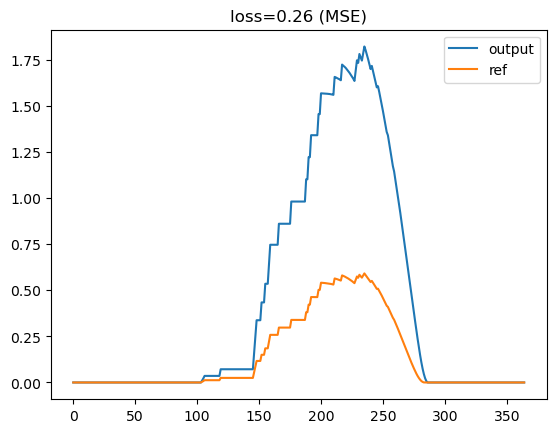

In [34]:
ref = torch.tensor(mean_swe_series_target)
param0 = 2. #torch.tensor(2.)
preds = integrate(param0)  # predictions
plt.plot(t,preds.detach(),label='output')
plt.plot(t,ref,label='ref')
plt.legend()
plt.title(f'loss={torch.nn.MSELoss()(preds, ref):.2f} (MSE)');

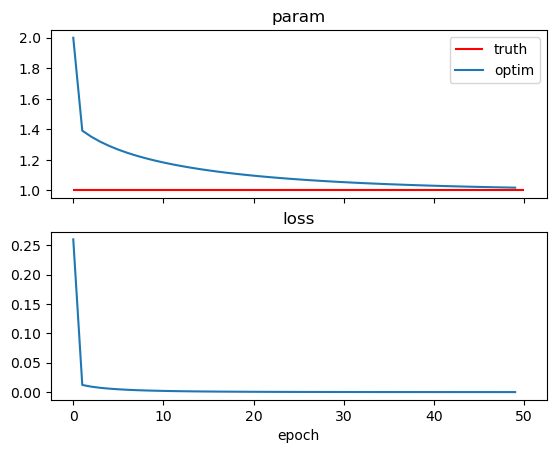

final param=1.02, final loss=0.00


In [100]:
def fit(model=integrate, param0=2., lr=0.5, epochs=50):
    out = np.zeros((2,epochs))
    param = torch.tensor(param0, requires_grad=True)
    for epoch in range(epochs):
        pred = model(param)
        loss = loss_func(pred, ref)
        out[0,epoch] = param.detach()
        out[1,epoch] = loss.detach()
        loss.backward()
        with torch.no_grad():
            param -= param.grad * lr
            param.grad.zero_()
    final_param = param.detach()

    fig,axs = plt.subplots(2,1, sharex=True)
    axs[0].hlines(1, xmin=0, xmax=epochs, label='truth', color='r')
    axs[0].plot(out[0,:],label='optim')
    axs[0].legend()
    axs[0].set_title('param')
    axs[1].plot(out[1,:], label='loss')
    axs[1].set_title('loss')
    axs[1].set_xlabel('epoch')
    plt.show()

    print(f'final param={final_param:.2f}, final loss={loss.detach():.2f}')

fit()

In [111]:
class MyModule(nn.Module):
    def __init__(self, init_param=param0):
        super().__init__()
        self.parameter = nn.Parameter(data=torch.tensor(init_param, dtype=torch.float32))

    def forward(self):
        return integrate(self.parameter)

In [129]:
def get_model():
    model = MyModule(init_param=param0)
    #model.parameter.data = torch.tensor(param0+1, dtype=torch.float32)
    return model, optim.SGD(model.parameters(), lr=0.5)

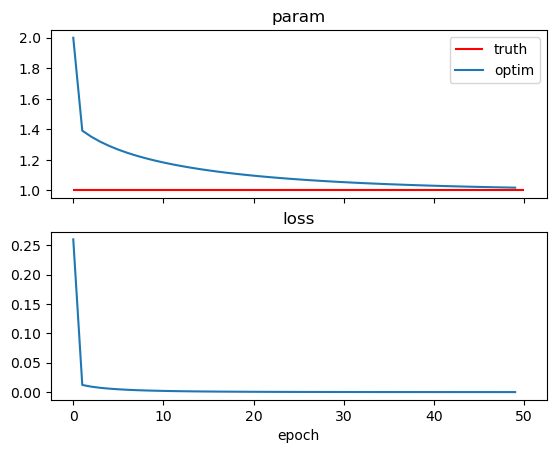

final param=1.02, final loss=0.00 (MSE)


In [131]:
epochs=50
model, opt = get_model()
out = np.zeros((2,epochs))
for epoch in range(epochs):
    opt.zero_grad()
    pred = model()
    loss = loss_func(pred, ref)
    out[0,epoch] = model.parameter.detach()
    out[1,epoch] = loss.detach()
    loss.backward()
    opt.step()

fig,axs = plt.subplots(2,1, sharex=True)
axs[0].hlines(1, xmin=0, xmax=epochs, label='truth', color='r')
axs[0].plot(out[0,:],label='optim')
axs[0].legend()
axs[0].set_title('param')
axs[1].plot(out[1,:], label='loss')
axs[1].set_title('loss')
axs[1].set_xlabel('epoch')
plt.show()  
print(f'final param={model.parameter.detach():.2f}, final loss={loss.detach():.2f} (MSE)')